<a href="https://colab.research.google.com/github/iplaycos1-crypto/MBA6636/blob/main/Credx.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [68]:
install.packages(c("tidyverse", "readxl", "kableExtra", "psych", "scorecard", "caret", "pROC", "randomForest"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [69]:
library(dplyr)
library(knitr)
library(kableExtra)
library(tidyverse)
library(readxl)
library(tibble)
library(psych)
library(scorecard)
library(caret)
library(pROC)
library(scales)
library(randomForest)

In [2]:
# Step 1: Define GitHub Raw URL
base_url <- "https://raw.githubusercontent.com/iplaycos1-crypto/MBA6636/main/"

# Step 2: Download both CSV files
files <- c("credit.csv", "demo.csv")
for (f in files) {
  download.file(
    url = paste0(base_url, f),
    destfile = f,
    mode = "wb"
  )
}
credit.dat <- read.csv("credit.csv")
demo.dat   <- read.csv("demo.csv")

# Step 3: Explore the datasets
# Display first six observations
head(credit.dat)
head(demo.dat)



,Application.ID,No.of.times.90.DPD.or.worse.in.last.6.months,No.of.times.60.DPD.or.worse.in.last.6.months,No.of.times.30.DPD.or.worse.in.last.6.months,No.of.times.90.DPD.or.worse.in.last.12.months,No.of.times.60.DPD.or.worse.in.last.12.months,No.of.times.30.DPD.or.worse.in.last.12.months,Avgas.CC.Utilization.in.last.12.months,No.of.trades.opened.in.last.6.months,No.of.trades.opened.in.last.12.months,No.of.PL.trades.opened.in.last.6.months,No.of.PL.trades.opened.in.last.12.months,No.of.Inquiries.in.last.6.months..excluding.home...auto.loans.,No.of.Inquiries.in.last.12.months..excluding.home...auto.loans.,Presence.of.open.home.loan,Outstanding.Balance,Total.No.of.Trades,Presence.of.open.auto.loan,Performance.Tag
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,954457215,0,0,0,0,0,0,4,1,2,0,0,0,0,1,2999395,4,0,0
2,432830445,0,0,0,0,0,0,3,1,2,0,0,0,0,0,3078,5,0,0
3,941387308,0,0,0,0,0,0,7,0,0,0,0,0,0,1,3004972,2,0,0
4,392161677,0,0,0,0,0,0,11,1,1,0,0,0,0,1,3355373,4,1,0
5,182011211,0,0,0,0,0,0,12,0,1,0,0,0,0,1,3014283,4,0,0
6,312196805,0,0,0,0,0,0,10,0,0,0,0,0,0,0,2569,1,0,0


,Application.ID,Age,Gender,Marital.Status..at.the.time.of.application.,No.of.dependents,Income,Education,Profession,Type.of.residence,No.of.months.in.current.residence,No.of.months.in.current.company,Performance.Tag
,<int>,<int>,<chr>,<chr>,<int>,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<int>
1,954457215,48,F,Married,2,40,Bachelor,SAL,Rented,113,56,0
2,432830445,31,M,Married,4,55,Professional,SE_PROF,Rented,112,46,0
3,941387308,32,M,Single,2,46,Bachelor,SE_PROF,Rented,104,49,0
4,392161677,43,M,Married,1,53,Bachelor,SE,Rented,94,53,0
5,182011211,35,F,Married,5,44,Professional,SAL,Rented,112,43,0
6,312196805,20,M,Married,1,39,Bachelor,SAL,,116,52,0


In [3]:
# Check variable names
names(credit.dat)

[1] "Application.ID"                                                 
 [2] "No.of.times.90.DPD.or.worse.in.last.6.months"                   
 [3] "No.of.times.60.DPD.or.worse.in.last.6.months"                   
 [4] "No.of.times.30.DPD.or.worse.in.last.6.months"                   
 [5] "No.of.times.90.DPD.or.worse.in.last.12.months"                  
 [6] "No.of.times.60.DPD.or.worse.in.last.12.months"                  
 [7] "No.of.times.30.DPD.or.worse.in.last.12.months"                  
 [8] "Avgas.CC.Utilization.in.last.12.months"                         
 [9] "No.of.trades.opened.in.last.6.months"                           
[10] "No.of.trades.opened.in.last.12.months"                          
[11] "No.of.PL.trades.opened.in.last.6.months"                        
[12] "No.of.PL.trades.opened.in.last.12.months"                       
[13] "No.of.Inquiries.in.last.6.months..excluding.home...auto.loans." 
[14] "No.of.Inquiries.in.last.12.months..excluding.home...auto.loans."
[15] "Presence.of.open.home.loan"                                     
[16] "Outstanding.Balance"                                            
[17] "Total.No.of.Trades"                                             
[18] "Presence.of.open.auto.loan"                                     
[19] "Performance.Tag"

In [ ]:
names(demo.dat)

[1] "Application.ID"                             
 [2] "Age"                                        
 [3] "Gender"                                     
 [4] "Marital.Status..at.the.time.of.application."
 [5] "No.of.dependents"                           
 [6] "Income"                                     
 [7] "Education"                                  
 [8] "Profession"                                 
 [9] "Type.of.residence"                          
[10] "No.of.months.in.current.residence"          
[11] "No.of.months.in.current.company"            
[12] "Performance.Tag"

In [ ]:
# Check data structure
str(credit.dat)

'data.frame':	71295 obs. of  19 variables:
 $ Application.ID                                                 : int  954457215 432830445 941387308 392161677 182011211 312196805 532217204 74788849 782743811 96964957 ...
 $ No.of.times.90.DPD.or.worse.in.last.6.months                   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ No.of.times.60.DPD.or.worse.in.last.6.months                   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ No.of.times.30.DPD.or.worse.in.last.6.months                   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ No.of.times.90.DPD.or.worse.in.last.12.months                  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ No.of.times.60.DPD.or.worse.in.last.12.months                  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ No.of.times.30.DPD.or.worse.in.last.12.months                  : int  0 0 0 0 0 0 0 0 1 0 ...
 $ Avgas.CC.Utilization.in.last.12.months                         : int  4 3 7 11 12 10 11 13 9 6 ...
 $ No.of.trades.opened.in.last.6.months                           : int  1 1 0 1 0 0 0 1 0 1 ...
 

In [ ]:
str(demo.dat)

'data.frame':	71295 obs. of  12 variables:
 $ Application.ID                             : int  954457215 432830445 941387308 392161677 182011211 312196805 532217204 74788849 782743811 96964957 ...
 $ Age                                        : int  48 31 32 43 35 20 42 34 30 22 ...
 $ Gender                                     : chr  "F" "M" "M" "M" ...
 $ Marital.Status..at.the.time.of.application.: chr  "Married" "Married" "Single" "Married" ...
 $ No.of.dependents                           : int  2 4 2 1 5 1 2 2 3 1 ...
 $ Income                                     : num  40 55 46 53 44 39 55 49 48 38 ...
 $ Education                                  : chr  "Bachelor" "Professional" "Bachelor" "Bachelor" ...
 $ Profession                                 : chr  "SAL" "SE_PROF" "SE_PROF" "SE" ...
 $ Type.of.residence                          : chr  "Rented" "Rented" "Rented" "Rented" ...
 $ No.of.months.in.current.residence          : int  113 112 104 94 112 116 104 108 115 111 ...


In [ ]:
# Check dimensions
dim(credit.dat)
dim(demo.dat)

[1] 71295    19

[1] 71295    12

In [ ]:
# Display descriptive statistics
summary(credit.dat)
summary(demo.dat)

 Application.ID      No.of.times.90.DPD.or.worse.in.last.6.months
 Min.   :1.004e+05   Min.   :0.0000                              
 1st Qu.:2.484e+08   1st Qu.:0.0000                              
 Median :4.976e+08   Median :0.0000                              
 Mean   :4.990e+08   Mean   :0.2703                              
 3rd Qu.:7.496e+08   3rd Qu.:0.0000                              
 Max.   :1.000e+09   Max.   :3.0000                              
                                                                 
 No.of.times.60.DPD.or.worse.in.last.6.months
 Min.   :0.0000                              
 1st Qu.:0.0000                              
 Median :0.0000                              
 Mean   :0.4305                              
 3rd Qu.:1.0000                              
 Max.   :5.0000                              
                                             
 No.of.times.30.DPD.or.worse.in.last.6.months
 Min.   :0.0000                              
 1st Qu.:0.0

 Application.ID           Age              Gender     
 Min.   :1.004e+05   Min.   :-3.00   Length   :71295  
 1st Qu.:2.484e+08   1st Qu.:37.00   N.unique :    3  
 Median :4.976e+08   Median :45.00   N.blank  :    2  
 Mean   :4.990e+08   Mean   :44.94   Min.nchar:    0  
 3rd Qu.:7.496e+08   3rd Qu.:53.00   Max.nchar:    1  
 Max.   :1.000e+09   Max.   :65.00                    
                                                      
 Marital.Status..at.the.time.of.application. No.of.dependents     Income    
 Length   :71295                             Min.   :1.000    Min.   :-0.5  
 N.unique :    3                             1st Qu.:2.000    1st Qu.:14.0  
 N.blank  :    6                             Median :3.000    Median :27.0  
 Min.nchar:    0                             Mean   :2.865    Mean   :27.2  
 Max.nchar:    7                             3rd Qu.:4.000    3rd Qu.:40.0  
                                             Max.   :5.000    Max.   :60.0  
                     

In [21]:
dup_ids <- demo.dat %>%
  count(Application.ID) %>%
  filter(n > 1) %>%
  pull(Application.ID)
print(dup_ids)

[1] 653287861 671989187 765011468


In [22]:
conflict_ids <- inner_join(
  demo.dat %>%
    filter(Application.ID %in% dup_ids) %>%
    select(Application.ID, pt_d = Performance.Tag),

  credit.dat %>%
    filter(Application.ID %in% dup_ids) %>%
    select(Application.ID, pt_c = Performance.Tag),

  by = "Application.ID"
) %>%
  filter(coalesce(pt_d, -1) != coalesce(pt_c, -1)) %>%
  distinct(Application.ID) %>%
  pull(Application.ID)

Warning message in inner_join(demo.dat %>% filter(Application.ID %in% dup_ids) %>% :
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 2 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


In [18]:
# Show conflict IDs and their count
cat("Number of conflicting Application IDs: ", length(conflict_ids), "\n")
if (length(conflict_ids) > 0) {
  print(conflict_ids)
} else {
  cat("No conflicting Application IDs found!\n")
}

Number of conflicting Application IDs:  1 
[1] 653287861


In [24]:
# Remove conflicting applicants
# Remove remaining duplicate IDs
demo_clean <- demo.dat %>%
  filter(!Application.ID %in% conflict_ids) %>%
  distinct(Application.ID, .keep_all = TRUE)

In [26]:
# Clean the credit dataset
credit_clean <- credit.dat %>%
  filter(!Application.ID %in% conflict_ids) %>%
  distinct(Application.ID, .keep_all = TRUE) %>%
  select(-Performance.Tag)

In [30]:
# Merge demo and credit into master
master <- inner_join(demo_clean, credit_clean, by = "Application.ID")
head(master)
str(master)
dim(master)

,Application.ID,Age,Gender,Marital.Status..at.the.time.of.application.,No.of.dependents,Income,Education,Profession,Type.of.residence,No.of.months.in.current.residence,⋯,No.of.trades.opened.in.last.6.months,No.of.trades.opened.in.last.12.months,No.of.PL.trades.opened.in.last.6.months,No.of.PL.trades.opened.in.last.12.months,No.of.Inquiries.in.last.6.months..excluding.home...auto.loans.,No.of.Inquiries.in.last.12.months..excluding.home...auto.loans.,Presence.of.open.home.loan,Outstanding.Balance,Total.No.of.Trades,Presence.of.open.auto.loan
,<int>,<int>,<chr>,<chr>,<int>,<dbl>,<chr>,<chr>,<chr>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,954457215,48,F,Married,2,40,Bachelor,SAL,Rented,113,⋯,1,2,0,0,0,0,1,2999395,4,0
2,432830445,31,M,Married,4,55,Professional,SE_PROF,Rented,112,⋯,1,2,0,0,0,0,0,3078,5,0
3,941387308,32,M,Single,2,46,Bachelor,SE_PROF,Rented,104,⋯,0,0,0,0,0,0,1,3004972,2,0
4,392161677,43,M,Married,1,53,Bachelor,SE,Rented,94,⋯,1,1,0,0,0,0,1,3355373,4,1
5,182011211,35,F,Married,5,44,Professional,SAL,Rented,112,⋯,0,1,0,0,0,0,1,3014283,4,0
6,312196805,20,M,Married,1,39,Bachelor,SAL,,116,⋯,0,0,0,0,0,0,0,2569,1,0


'data.frame':	71291 obs. of  29 variables:
 $ Application.ID                                                 : int  954457215 432830445 941387308 392161677 182011211 312196805 532217204 74788849 782743811 96964957 ...
 $ Age                                                            : int  48 31 32 43 35 20 42 34 30 22 ...
 $ Gender                                                         : chr  "F" "M" "M" "M" ...
 $ Marital.Status..at.the.time.of.application.                    : chr  "Married" "Married" "Single" "Married" ...
 $ No.of.dependents                                               : int  2 4 2 1 5 1 2 2 3 1 ...
 $ Income                                                         : num  40 55 46 53 44 39 55 49 48 38 ...
 $ Education                                                      : chr  "Bachelor" "Professional" "Bachelor" "Bachelor" ...
 $ Profession                                                     : chr  "SAL" "SE_PROF" "SE_PROF" "SE" ...
 $ Type.of.residence         

[1] 71291    29

In [32]:
# Define credit bureau variables
bureau_vars <- c(
  "No_of_times_90_DPD_or_worse_in_last_6_months",
  "No_of_times_60_DPD_or_worse_in_last_6_months",
  "No_of_times_30_DPD_or_worse_in_last_6_months",
  "No_of_times_90_DPD_or_worse_in_last_12_months",
  "No_of_times_60_DPD_or_worse_in_last_12_months",
  "No_of_times_30_DPD_or_worse_in_last_12_months",
  "No_of_trades_opened_in_last_6_months",
  "No_of_trades_opened_in_last_12_months",
  "No_of_PL_trades_opened_in_last_6_months",
  "No_of_PL_trades_opened_in_last_12_months",
  "No_of_Inquiries_in_last_6_months_excluding_home_auto_loans",
  "No_of_Inquiries_in_last_12_months_excluding_home_auto_loans",
  "Presence_of_open_home_loan",
  "Outstanding_Balance",
  "Total_No_of_Trades",
  "Presence_of_open_auto_loan"
)
# Define the credit utilization variable
util_var <- "Avgas_CC_Utilization_in_last_12_months"

In [36]:
# Dynamically retrieve the exact column names from the master data frame
bureau_vars_clean <- names(master)[grepl("No.of.times|No.of.trades|No.of.PL.trades|Inquiries|Presence.of.open|Outstanding.Balance|Total.No.of.Trades", names(master))]
util_var_clean <- "Avgas.CC.Utilization.in.last.12.months"

master <- master %>%
  mutate(
    bureau_no_hit = if_else(
      rowSums(across(all_of(bureau_vars_clean), ~ coalesce(.x, 0) == 0)) == length(bureau_vars_clean) &
        is.na(.data[[util_var_clean]]),
      1L, 0L
    ),
    no_other_card = if_else(is.na(.data[[util_var_clean]]), 1L, 0L),
    Age    = if_else(Age < 18 | Age > 100, NA_real_, as.numeric(Age)),
    Income = if_else(Income <= 0, NA_real_, as.numeric(Income))
  )

In [38]:
# Separate performance applicants and rejected applicants
perf_df     <- master %>% filter(!is.na(Performance.Tag)) %>% mutate(target = as.integer(Performance.Tag))
rejected_df <- master %>% filter(is.na(Performance.Tag))

In [ ]:

# Missing value summary
missing.summary <- data.frame(
  Variable = names(credit.dat),
  Missing_Count = colSums(is.na(credit.dat)),
  Missing_Percentage = round(
    colMeans(is.na(credit.dat)) * 100, 2
  )
)
print(missing.summary)


                                                                                                                       Variable
Application.ID                                                                                                   Application.ID
No.of.times.90.DPD.or.worse.in.last.6.months                                       No.of.times.90.DPD.or.worse.in.last.6.months
No.of.times.60.DPD.or.worse.in.last.6.months                                       No.of.times.60.DPD.or.worse.in.last.6.months
No.of.times.30.DPD.or.worse.in.last.6.months                                       No.of.times.30.DPD.or.worse.in.last.6.months
No.of.times.90.DPD.or.worse.in.last.12.months                                     No.of.times.90.DPD.or.worse.in.last.12.months
No.of.times.60.DPD.or.worse.in.last.12.months                                     No.of.times.60.DPD.or.worse.in.last.12.months
No.of.times.30.DPD.or.worse.in.last.12.months                                     No.of.times.30.DPD.or.

In [39]:
# Display the final dataset sizes
cat("Clean master:", nrow(master),
    "| Performance sample:", nrow(perf_df),
    "| Rejected sample:", nrow(rejected_df), "\n")

Clean master: 71291 | Performance sample: 69866 | Rejected sample: 1425 


In [41]:
# Important checks
# Are there still duplicate IDs
master %>%
  count(Application.ID) %>%
  filter(n > 1)


Application.ID,n
<int>,<int>


[1] 0

In [ ]:
sum(master$Age < 18 | master$Age > 100, na.rm = TRUE)

In [44]:
# Check the distribution of performance tags.
table(master$Performance_Tag, useNA = "ifany")
# Check the two special bureau flags
table(master$bureau_no_hit)
table(master$no_other_card)

< table of extent 0 >


    0     1 
70725   566 


    0     1 
70233  1058 

In [43]:
# Verify the default rate
perf_df %>%
  summarise(
    Total_Applicants = n(),
    Defaults = sum(target == 1),
    Non_Defaults = sum(target == 0),
    Default_Rate = mean(target == 1) * 100
  )

Total_Applicants,Defaults,Non_Defaults,Default_Rate
<int>,<int>,<int>,<dbl>
69866,2947,66919,4.218075


# A tibble: 10 × 9
   variable   n_non_na n_missing missing_pct    mean median      sd   min    max
   <chr>         <int>     <int>       <dbl>   <dbl>  <dbl>   <dbl> <dbl>  <dbl>
 1 Age           69801        65        0.09 4.50e+1     45 9.88e+0    18 6.5 e1
 2 Income        69759       107        0.15 2.74e+1     27 1.54e+1     1 6   e1
 3 No.of.dep…    69863         3        0    2.86e+0      3 1.39e+0     1 5   e0
 4 No.of.mon…    69866         0        0    3.46e+1     10 3.69e+1     6 1.26e2
 5 No.of.mon…    69866         0        0    3.42e+1     34 2.04e+1     3 1.33e2
 6 Avgas.CC.…    68843      1023        1.46 2.93e+1     15 2.95e+1     0 1.13e2
 7 Outstandi…    69594       272        0.39 1.25e+6 774242 1.29e+6     0 5.22e6
 8 Total.No.…    69866         0        0    8.17e+0      6 7.15e+0     0 4.4 e1
 9 No.of.tim…    69866         0        0    7.3 e-1      0 1.24e+0     0 9   e0
10 No.of.tim…    69866         0        0    4.1 e-1      0 7.6 e-1     0 5   e0

--- Brea

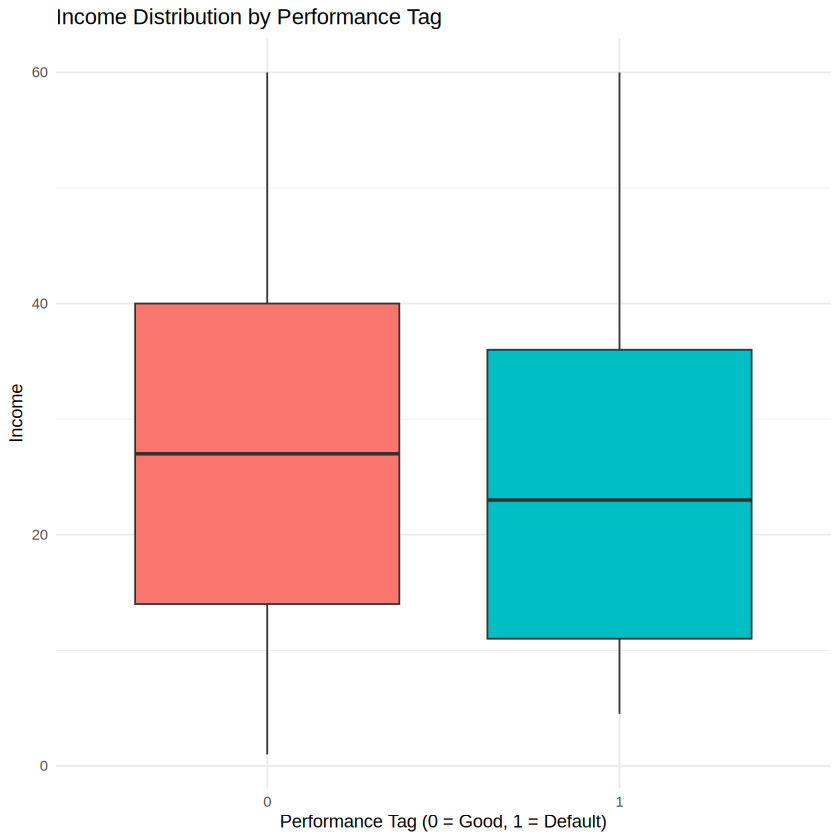

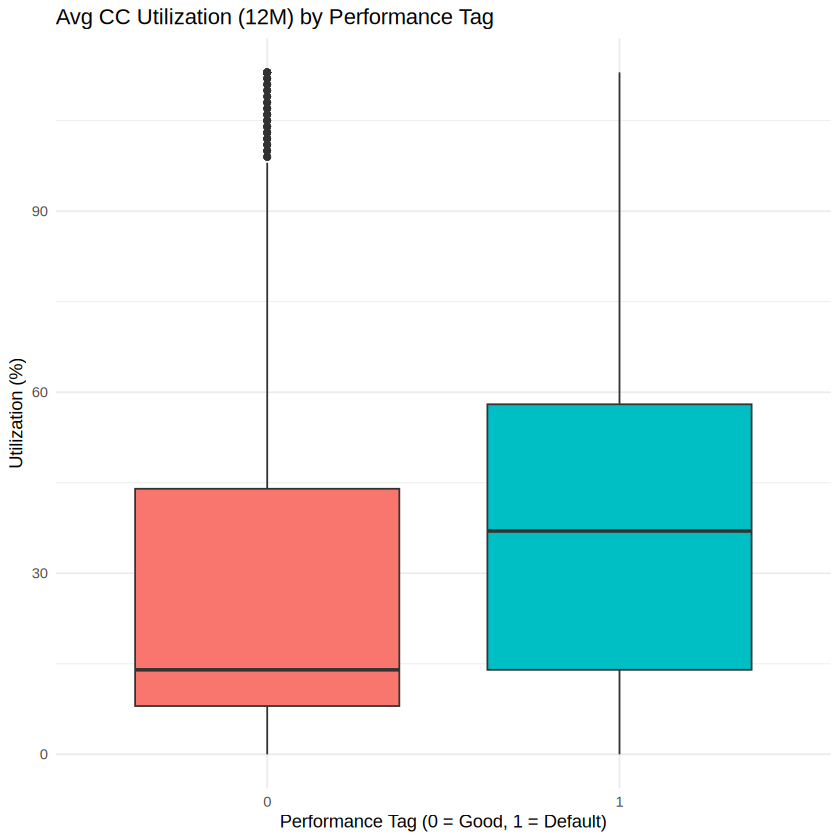

In [48]:
# Step 1 (Continued): Descriptive Analysis of Key Variables (R)

# 1. Numeric / Continuous & Count Variables Summary on Clean Performance Sample
key_num_vars <- c(
  "Age",
  "Income",
  "No.of.dependents",
  "No.of.months.in.current.residence",
  "No.of.months.in.current.company",
  "Avgas.CC.Utilization.in.last.12.months",
  "Outstanding.Balance",
  "Total.No.of.Trades",
  "No.of.times.30.DPD.or.worse.in.last.12.months",
  "No.of.times.90.DPD.or.worse.in.last.12.months"
)

num_desc <- map_dfr(key_num_vars, function(col) {
  x <- perf_df[[col]]
  tibble(
    variable    = col,
    n_non_na    = sum(!is.na(x)),
    n_missing   = sum(is.na(x)),
    missing_pct = round(mean(is.na(x)) * 100, 2),
    mean        = round(mean(x, na.rm = TRUE), 2),
    median      = round(median(x, na.rm = TRUE), 2),
    sd          = round(sd(x, na.rm = TRUE), 2),
    min         = round(min(x, na.rm = TRUE), 2),
    max         = round(max(x, na.rm = TRUE), 2)
  )
})

print(num_desc, n = 20)

# 2. Categorical Variables: Distribution & Default Rate by Category
key_cat_vars <- c(
  "Gender",
  "Marital.Status..at.the.time.of.application.",
  "Education",
  "Profession",
  "Type.of.residence"
)

for (col in key_cat_vars) {
  cat("\n--- Breakdown for:", col, "---\n")
  cat_tbl <- perf_df %>%
    mutate(grp = replace_na(as.character(.data[[col]]), "MISSING")) %>%
    group_by(grp) %>%
    summarise(
      applicants       = n(),
      share_pct        = round(n() / nrow(perf_df) * 100, 2),
      defaults         = sum(target == 1),
      default_rate_pct = round(mean(target == 1) * 100, 2),
      .groups = "drop"
    ) %>%
    arrange(desc(applicants))
  print(cat_tbl, n = 20)
}

# 3. Default Rate Comparison: Good (0) vs. Bad (1) on Key Numeric Predictors
perf_df %>%
  group_by(target) %>%
  summarise(
    n                    = n(),
    mean_age             = round(mean(Age, na.rm = TRUE), 1),
    median_income        = round(median(Income, na.rm = TRUE), 1),
    mean_cc_util_12m     = round(mean(Avgas.CC.Utilization.in.last.12.months, na.rm = TRUE), 1),
    median_balance       = round(median(Outstanding.Balance, na.rm = TRUE), 0),
    mean_30dpd_12m       = round(mean(No.of.times.30.DPD.or.worse.in.last.12.months, na.rm = TRUE), 2),
    mean_90dpd_12m       = round(mean(No.of.times.90.DPD.or.worse.in.last.12.months, na.rm = TRUE), 2),
    .groups = "drop"
  ) %>%
  print()

# 4. Visual Summary: Income & CC Utilization by Performance Tag
p1 <- ggplot(perf_df %>% filter(!is.na(Income)), aes(x = factor(target), y = Income, fill = factor(target))) +
  geom_boxplot(outlier.alpha = 0.15, show.legend = FALSE) +
  labs(title = "Income Distribution by Performance Tag", x = "Performance Tag (0 = Good, 1 = Default)", y = "Income") +
  theme_minimal()

p2 <- ggplot(perf_df %>% filter(!is.na(Avgas.CC.Utilization.in.last.12.months)),
             aes(x = factor(target), y = Avgas.CC.Utilization.in.last.12.months, fill = factor(target))) +
  geom_boxplot(outlier.alpha = 0.15, show.legend = FALSE) +
  labs(title = "Avg CC Utilization (12M) by Performance Tag", x = "Performance Tag (0 = Good, 1 = Default)", y = "Utilization (%)") +
  theme_minimal()

print(p1)
print(p2)

In [55]:
# Step 2: WOE Transformation and Information Value
calc_woe_iv <- function(df, col_name, target_col = "target", bins = 10, smooth = 0.5) {
  # Safely fetch column
  if (!col_name %in% names(df)) {
    stop(paste("Column not found in data frame:", col_name))
  }
  x <- df[[col_name]]
  y <- df[[target_col]]
  is_bin_flag <- is.numeric(x) && all(na.omit(unique(x)) %in% c(0, 1))

  if (is.numeric(x) && !is_bin_flag) {
    non_na <- x[!is.na(x)]
    if (length(unique(non_na)) <= bins) {
      breaks <- NULL
      bin_vec <- ifelse(is.na(x), "MISSING", as.character(x))
    } else {
      breaks <- unique(quantile(non_na, probs = seq(0, 1, length.out = bins + 1), na.rm = TRUE))
      bin_vec <- ifelse(is.na(x), "MISSING", as.character(cut(x, breaks = breaks, include.lowest = TRUE, right = TRUE)))
    }
  } else {
    breaks <- NULL
    bin_vec <- ifelse(is.na(x), "MISSING", as.character(x))
    freq <- prop.table(table(bin_vec[bin_vec != "MISSING"]))
    rare <- names(freq[freq < 0.01])
    bin_vec <- ifelse(bin_vec %in% rare, "OTHER", bin_vec)
  }

  tbl <- tibble(bin = bin_vec, y = y) %>%
    group_by(bin) %>%
    summarise(total = n(), bad = sum(y == 1), good = sum(y == 0), .groups = "drop")

  tot_g <- sum(tbl$good)
  tot_b <- sum(tbl$bad)
  k     <- nrow(tbl)

  tbl <- tbl %>%
    mutate(
      p_good = (good + smooth) / (tot_g + smooth * k),
      p_bad  = (bad + smooth) / (tot_b + smooth * k),
      woe    = log(p_good / p_bad),
      iv_bin = (p_good - p_bad) * woe
    )

  list(iv = sum(tbl$iv_bin), table = tbl, breaks = breaks, is_cont = (is.numeric(x) && !is_bin_flag))
}

map_woe <- function(x, woe_obj) {
  if (woe_obj$is_cont) {
    if (is.null(woe_obj$breaks)) {
      b <- ifelse(is.na(x), "MISSING", as.character(x))
    } else {
      b <- ifelse(is.na(x), "MISSING", as.character(cut(x, breaks = woe_obj$breaks, include.lowest = TRUE, right = TRUE)))
    }
  } else {
    b <- ifelse(is.na(x), "MISSING", as.character(x))
    b <- ifelse(b %in% woe_obj$table$bin, b, "OTHER")
  }
  lookup <- setNames(woe_obj$table$woe, woe_obj$table$bin)
  out <- unname(lookup[b])
  out[is.na(out)] <- 0
  out
}

# Map columns using the period-based format matching perf_df
demo_cols <- c(
  "Age", "Gender", "Marital.Status..at.the.time.of.application.",
  "No.of.dependents", "Income", "Education", "Profession",
  "Type.of.residence", "No.of.months.in.current.residence",
  "No.of.months.in.current.company"
)
cred_cols <- c(bureau_vars_clean, util_var_clean, "bureau_no_hit", "no_other_card")
all_cols  <- c(demo_cols, cred_cols)

woe_list <- setNames(lapply(all_cols, function(c) calc_woe_iv(perf_df, c)), all_cols)

iv_summary <- tibble(
  feature = all_cols,
  domain  = if_else(all_cols %in% demo_cols, "Demographic", "Credit Bureau"),
  IV      = map_dbl(all_cols, ~ woe_list[[.x]]$iv)
) %>% arrange(desc(IV))

print(iv_summary, n = 35)

selected_cols <- iv_summary %>% filter(IV >= 0.02) %>% pull(feature)
woe_data <- perf_df %>% select(Application.ID, target)
for (c in selected_cols) {
  woe_data[[c]] <- map_woe(perf_df[[c]], woe_list[[c]])
}
write_csv(woe_data, "woe_data.csv")

# A tibble: 29 × 3
   feature                                                        domain      IV
   <chr>                                                          <chr>    <dbl>
 1 Avgas.CC.Utilization.in.last.12.months                         Credi… 3.16e-1
 2 No.of.trades.opened.in.last.12.months                          Credi… 2.93e-1
 3 No.of.PL.trades.opened.in.last.12.months                       Credi… 2.59e-1
 4 No.of.times.30.DPD.or.worse.in.last.6.months                   Credi… 2.45e-1
 5 No.of.Inquiries.in.last.12.months..excluding.home...auto.loan… Credi… 2.45e-1
 6 Outstanding.Balance                                            Credi… 2.45e-1
 7 Total.No.of.Trades                                             Credi… 2.32e-1
 8 No.of.PL.trades.opened.in.last.6.months                        Credi… 2.24e-1
 9 No.of.times.30.DPD.or.worse.in.last.12.months                  Credi… 2.20e-1
10 No.of.times.90.DPD.or.worse.in.last.12.months                  Credi… 2.17e-1
11 No.of.

### Step 2: WOE Transformation and Information Value Analysis

Weight of Evidence (WOE) transformation and Information Value (IV) analysis were performed on 29 demographic and credit bureau predictors using the labeled performance dataset.

Continuous variables were divided into quantile-based bins, while categorical and binary variables were treated as separate categories. Missing observations were retained as a separate "MISSING" category. A smoothing factor of 0.5 was applied to avoid infinite WOE values when a bin contained zero good or bad observations.

WOE was calculated using the natural logarithm of the proportion of good applicants divided by the proportion of bad applicants in each bin. The IV of each predictor was then calculated by summing the contributions of all its bins.

The results indicate that credit bureau variables generally have considerably greater predictive power than demographic variables. Credit card utilization recorded the highest IV of 0.316, followed by the number of trades opened in the last 12 months (0.293), personal loan trades opened in the last 12 months (0.259), and recent payment delinquency indicators.

Among demographic variables, the number of months in current residence had the highest IV (0.0709), followed by income (0.0439) and employment tenure (0.0227). Other demographic characteristics, including age, gender, education, and marital status, showed relatively weak individual predictive power.

Using an IV threshold of 0.02, 18 out of the 29 predictors were selected for subsequent modeling. These variables were transformed into WOE values and exported to `woe_data.csv` for logistic regression analysis.

Overall, the findings suggest that applicants' historical credit behavior, credit utilization, and borrowing activities provide more informative indicators of default risk than their demographic characteristics in this dataset.

ABOVE STEP 2

In [61]:
# Step 3: Model Building

set.seed(42)
idx <- createDataPartition(woe_data$target, p = 0.70, list = FALSE)
train_woe <- woe_data[idx, ]
test_woe  <- woe_data[-idx, ]

demo_selected <- intersect(selected_cols, demo_cols)

glm_demo <- glm(
  as.formula(paste("target ~", paste(demo_selected, collapse = " + "))),
  data = train_woe, family = binomial(link = "logit")
)

glm_combined <- glm(
  as.formula(paste("target ~", paste(selected_cols, collapse = " + "))),
  data = train_woe, family = binomial(link = "logit")
)

summary(glm_combined)


Call:
glm(formula = as.formula(paste("target ~", paste(selected_cols, 
    collapse = " + "))), family = binomial(link = "logit"), data = train_woe)

Coefficients:
                                                                Estimate
(Intercept)                                                     -3.13137
Avgas.CC.Utilization.in.last.12.months                          -0.37140
No.of.trades.opened.in.last.12.months                           -0.29527
No.of.PL.trades.opened.in.last.12.months                         0.01205
No.of.times.30.DPD.or.worse.in.last.6.months                    -0.16124
No.of.Inquiries.in.last.12.months..excluding.home...auto.loans. -0.25027
Outstanding.Balance                                             -0.23882
Total.No.of.Trades                                               0.17934
No.of.PL.trades.opened.in.last.6.months                         -0.02557
No.of.times.30.DPD.or.worse.in.last.12.months                   -0.27614
No.of.times.90.DPD.or.worse.in.l

My conclusion:Your combined logistic regression model provides evidence that credit bureau variables, particularly credit card utilization and recent credit activity, contain useful information for predicting credit default. Income also contributes significantly. However, some selected predictors are statistically insignificant, possibly because of overlapping information among credit bureau variables. You should now compare the demographic and combined models and evaluate their predictive performance on the testing dataset.

The most important next step is to calculate the AUC and ROC curve for both models. That will help you determine whether the combined model actually predicts default better than the demographic-only model.

above step 3

In [71]:
# Step 4: Model Evaluation & Rejected Applicant Analysis
get_perf_metrics <- function(actual, prob, label) {
  r <- roc(actual, prob, quiet = TRUE)
  a <- as.numeric(auc(r))
  tibble(
    Model = label,
    AUC   = round(a, 4),
    Gini  = round(2 * a - 1, 4),
    KS    = round(max(abs(r$sensitivities - (1 - r$specificities))), 4),
    Brier = round(mean((prob - actual)^2), 4)
  )
}

p_demo_test <- predict(glm_demo, newdata = test_woe, type = "response")
p_comb_test <- predict(glm_combined, newdata = test_woe, type = "response")

print(bind_rows(
  get_perf_metrics(test_woe$target, p_demo_test, "Demographic Logistic"),
  get_perf_metrics(test_woe$target, p_comb_test, "Combined Logistic")
))

# Map application ID safely using the period format
rej_woe <- rejected_df %>% select(Application.ID)
for (c in selected_cols) {
  rej_woe[[c]] <- map_woe(rejected_df[[c]], woe_list[[c]])
}
rej_woe$pred_pd <- predict(glm_combined, newdata = rej_woe, type = "response")

cat("Mean PD — Approved (Test):", percent(mean(p_comb_test), accuracy = 0.01),
    "| Rejected:", percent(mean(rej_woe$pred_pd), accuracy = 0.01), "\n")

# A tibble: 2 × 5
  Model                  AUC  Gini    KS  Brier
  <chr>                <dbl> <dbl> <dbl>  <dbl>
1 Demographic Logistic 0.600 0.200 0.158 0.0406
2 Combined Logistic    0.679 0.359 0.287 0.0402
Mean PD — Approved (Test): 4.16% | Rejected: 8.71% 


### Logistic Regression Model Performance and Rejected-Applicant Analysis

Two logistic regression models were developed using a 70% training sample and evaluated on a 30% testing sample. The first model included demographic variables only, while the second combined demographic and credit bureau variables selected through Information Value analysis.

The combined model outperformed the demographic-only model across all four performance measures. Its AUC increased from 0.600 to 0.679, while the Gini coefficient increased from 0.200 to 0.359. The KS statistic also improved from 0.158 to 0.287, indicating better separation between good and bad applicants. The Brier score decreased slightly from 0.0406 to 0.0402, suggesting a small improvement in probability prediction accuracy.

These results indicate that credit bureau information provides additional predictive value beyond demographic characteristics alone. However, the combined model's AUC of 0.679 suggests that its discriminatory power is moderate and could be improved further.

The combined model was subsequently applied to applicants without observed performance outcomes. The average predicted probability of default was 4.16% for approved applicants in the testing sample, compared with 8.71% for rejected applicants. This difference suggests that rejected applicants had a higher estimated credit risk based on the fitted model. However, because rejected applicants have no observed repayment outcomes, these probabilities should be interpreted as model estimates rather than actual default rates.

above step 4

In [64]:
# Step 5: Application Scorecard & Cutoff Determination
factor_pts <- 20 / log(2)
offset_pts <- 400 - factor_pts * log(10)

pd_to_points <- function(pd, eps = 1e-6) {
  p <- pmin(pmax(pd, eps), 1 - eps)
  offset_pts + factor_pts * log((1 - p) / p)
}

woe_data$pred_pd <- predict(glm_combined, newdata = woe_data, type = "response")
woe_data$score   <- pd_to_points(woe_data$pred_pd)
rej_woe$score    <- pd_to_points(rej_woe$pred_pd)

cat("Approved Score Summary:\n"); print(round(summary(woe_data$score), 1))
cat("Rejected Score Summary:\n"); print(round(summary(rej_woe$score), 1))

cutoff_eval <- map_dfr(seq(395, 445, by = 5), function(cut_pt) {
  app <- woe_data %>% filter(score >= cut_pt)
  tibble(
    cutoff            = cut_pt,
    approval_rate_pct = round(nrow(app) / nrow(woe_data) * 100, 1),
    approved_bad_pct  = round(mean(app$target) * 100, 2),
    bads_blocked_pct  = round(sum(woe_data$target[woe_data$score < cut_pt]) / sum(woe_data$target) * 100, 1)
  )
})
print(cutoff_eval, n = 20)

Approved Score Summary:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  390.5   412.7   429.5   429.4   448.5   464.3 
Rejected Score Summary:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  387.7   398.0   400.8   401.8   404.5   436.4 
# A tibble: 11 × 4
   cutoff approval_rate_pct approved_bad_pct bads_blocked_pct
    <dbl>             <dbl>            <dbl>            <dbl>
 1    395              99.7             4.19              1.1
 2    400              95.4             3.94             10.9
 3    405              86.4             3.53             27.8
 4    410              78.7             3.18             40.6
 5    415              72               2.89             50.6
 6    420              64.3             2.57             60.7
 7    425              56.7             2.29             69.2
 8    430              49.3             2.05             76.1
 9    435              41.9             1.81             82  
10    440              35.9             1.62           

### Credit Scoring and Approval Cutoff Analysis

The predicted probabilities of default from the combined logistic regression model were converted into credit scores using the Points to Double the Odds (PDO) method. The scoring system was calibrated with a base score of 400 at a 10% probability of default and a PDO of 20 points. Consequently, applicants with lower predicted default probabilities received higher credit scores.

The score distribution indicated that labelled applicants had a mean score of 429.4, compared with 401.8 for rejected applicants. This difference suggests that rejected applicants generally had higher estimated credit risk.

An approval cutoff analysis was then conducted using score thresholds ranging from 395 to 445. The results demonstrated a trade-off between approval volume and credit risk. At a cutoff of 400, the approval rate was 95.4%, while 10.9% of actual bad applicants were blocked. Increasing the cutoff to 420 reduced the approval rate to 64.3%, while the proportion of bad applicants blocked increased to 60.7%. At a more conservative cutoff of 445, only 29.9% of applicants were approved, but 89.9% of actual bad applicants were blocked.

Overall, the analysis demonstrates that increasing the minimum credit score reduces the proportion of bad applicants accepted by the bank, but also reduces lending volume. Therefore, the selection of an appropriate cutoff should reflect the bank's risk appetite, profitability objectives and desired balance between credit risk and customer acquisition.

above step 5

In [73]:
# Step 6: Financial Benefit Assessment & Recommendation
annual_apps      <- 50000  # Example assumption: 50,000 applications/year
loss_per_default <- 2500   # Example assumption: $2,500 net loss per default
cutoff_choice    <- 410    # Example cutoff

base_bad <- mean(woe_data$target)
app_df   <- woe_data %>% filter(score >= cutoff_choice)
app_rate <- nrow(app_df) / nrow(woe_data)
rej_rate <- 1 - app_rate
new_bad  <- mean(app_df$target)

exp_app_n        <- annual_apps * app_rate
exp_rej_n        <- annual_apps * rej_rate
defaults_avoided <- exp_app_n * (base_bad - new_bad)
loss_avoided_usd <- defaults_avoided * loss_per_default

cat(sprintf("Cutoff %d -> Auto-Approve: %s (%.1f%%) | Auto-Reject: %s (%.1f%%)\n",
            cutoff_choice, comma(round(exp_app_n)), app_rate * 100,
            comma(round(exp_rej_n)), rej_rate * 100))
cat(sprintf("Approved Bad Rate: %.2f%% (vs %.2f%% baseline) | Est. Defaults Avoided: %s | Est. Loss Avoided: %s\n",
            new_bad * 100, base_bad * 100, comma(round(defaults_avoided)), dollar(round(loss_avoided_usd))))

Cutoff 410 -> Auto-Approve: 39,357 (78.7%) | Auto-Reject: 10,643 (21.3%)
Approved Bad Rate: 3.18% (vs 4.22% baseline) | Est. Defaults Avoided: 407 | Est. Loss Avoided: $1,017,537


### Conclusion and Business Recommendations

The credit risk modelling analysis demonstrates the potential value of using credit bureau information and logistic regression to improve lending decisions. The combined model, which incorporates demographic and credit bureau variables, outperformed the demographic-only model, achieving an AUC of 0.679 compared with 0.600. This indicates that credit history and repayment behaviour provide additional predictive information for identifying potential defaults.

Based on the credit scoring and cutoff analysis, a minimum score of 410 was selected as an illustrative lending threshold. Under this policy, approximately 78.7% of annual applicants (39,357 out of 50,000) would be automatically approved, while 21.3% would be rejected. The historical bad rate among approved applicants would decrease from the overall baseline of 4.22% to 3.18%, representing a relative reduction of approximately 24.6%.

Assuming an annual application volume of 50,000 and an average net loss of $2,500 per default, the proposed policy is estimated to avoid approximately 407 defaults and $1.02 million in annual credit losses.

Overall, the results suggest that the proposed credit scoring system could help the bank achieve a balance between customer acquisition and credit risk management. It offers a practical approach to identifying lower-risk applicants while reducing potential credit losses. However, the estimated financial benefits should be treated as illustrative rather than guaranteed. Further validation using an independent testing dataset, improved model calibration, and more realistic loss assumptions is recommended before implementing the scoring system in actual lending decisions.

above step 6

In [70]:
# Step 7 : Advanced Model & Sensitivity Analysis

set.seed(42)
rf_fit <- randomForest(
  x = as.matrix(train_woe %>% select(all_of(selected_cols))),
  y = factor(train_woe$target),
  ntree = 250,
  nodesize = 30
)
p_rf_test <- predict(rf_fit, newdata = as.matrix(test_woe %>% select(all_of(selected_cols))), type = "prob")[, "1"]

print(bind_rows(
  get_perf_metrics(test_woe$target, p_comb_test, "Combined Logistic"),
  get_perf_metrics(test_woe$target, p_rf_test, "Random Forest")
))

sens_tbl <- expand_grid(
  cutoff = c(405, 410, 415, 420),
  lgd    = c(1500, 2500, 3500)
) %>%
  rowwise() %>%
  mutate(
    app_pct      = round(mean(woe_data$score >= cutoff) * 100, 1),
    bad_pct      = round(mean(woe_data$target[woe_data$score >= cutoff]) * 100, 2),
    loss_avoided = round(
      annual_apps * mean(woe_data$score >= cutoff) *
        (base_bad - mean(woe_data$target[woe_data$score >= cutoff])) * lgd, 0
    )
  ) %>%
  ungroup()

print(sens_tbl, n = 20)

# A tibble: 2 × 5
  Model               AUC  Gini    KS  Brier
  <chr>             <dbl> <dbl> <dbl>  <dbl>
1 Combined Logistic 0.679 0.359 0.287 0.0402
2 Random Forest     0.628 0.257 0.233 0.042 
# A tibble: 12 × 5
   cutoff   lgd app_pct bad_pct loss_avoided
    <dbl> <dbl>   <dbl>   <dbl>        <dbl>
 1    405  1500    86.4    3.53       449110
 2    405  2500    86.4    3.53       748517
 3    405  3500    86.4    3.53      1047924
 4    410  1500    78.7    3.18       610522
 5    410  2500    78.7    3.18      1017537
 6    410  3500    78.7    3.18      1424552
 7    415  1500    72      2.89       714958
 8    415  2500    72      2.89      1191596
 9    415  3500    72      2.89      1668235
10    420  1500    64.3    2.57       792878
11    420  2500    64.3    2.57      1321463
12    420  3500    64.3    2.57      1850048


### Final Conclusion and Business Recommendations

This credit risk modelling project developed and evaluated predictive models to identify potential loan defaults and support credit approval decisions.

The comparison between logistic regression and Random Forest showed that logistic regression achieved better predictive performance across all four evaluation measures. The logistic regression model obtained an AUC of 0.679, Gini coefficient of 0.359, KS statistic of 0.287 and Brier score of 0.0402, outperforming Random Forest, which achieved an AUC of 0.628, Gini coefficient of 0.257, KS statistic of 0.233 and Brier score of 0.0420. Therefore, logistic regression was selected as the preferred model among the two evaluated approaches.

The model's predicted probabilities of default were converted into credit scores using a Points to Double the Odds (PDO) approach. Based on the approval cutoff analysis, a score of 410 was selected as an illustrative balanced lending policy. Under the assumption of 50,000 annual applications, this policy would approve approximately 78.7% of applicants and reject 21.3%. The historical bad rate among approved applicants would decrease from 4.22% to 3.18%.

The financial sensitivity analysis further demonstrated that the estimated benefits depend on both the approval cutoff and the assumed loss per default. At a cutoff of 410 and an assumed loss of $2,500 per default, the estimated annual loss avoided was approximately $1.02 million. Increasing the cutoff to 420 reduced the approval rate to 64.3% and the approved bad rate to 2.57%, while increasing the estimated loss avoided to approximately $1.32 million under the same loss assumption.

Overall, the analysis demonstrates the potential value of integrating credit bureau information, logistic regression and credit scoring techniques into lending decisions. The proposed approach could improve risk selection while maintaining a reasonable level of customer approval. However, the final cutoff should be determined by balancing expected credit losses against the revenue and business opportunities associated with approving creditworthy customers.

Before practical implementation, the model should undergo further validation using an independent testing dataset, appropriate WOE training procedures, probability calibration and realistic credit loss assumptions.

stop

In [51]:
# Create the WOE and IV calculation function
alc_woe_iv <- function(df, col_name, target_col = "target", bins = 10, smooth = 0.5) {
  x <- df[[col_name]]
  y <- df[[target_col]]
  is_bin_flag <- is.numeric(x) && all(na.omit(unique(x)) %in% c(0, 1))

  # Compute overall Good and Bad counts
  total_bad  <- sum(y == 1, na.rm = TRUE)
  total_good <- sum(y == 0, na.rm = TRUE)

  # Discretize continuous variable into bins if it's not binary
  if (!is_bin_flag && is.numeric(x)) {
    breaks <- unique(quantile(x, probs = seq(0, 1, length.out = bins + 1), na.rm = TRUE))
    if (length(breaks) > 1) {
      x <- cut(x, breaks = breaks, include.lowest = TRUE)
    }
  }

  # Aggregate counts per category/bin
  summary_df <- tibble(grp = as.character(x), y = y) %>%
    group_by(grp) %>%
    summarise(
      bads  = sum(y == 1, na.rm = TRUE),
      goods = sum(y == 0, na.rm = TRUE),
      .groups = "drop"
    ) %>%
    mutate(
      bad_rate  = (bads + smooth) / (total_bad + smooth * 2),
      good_rate = (goods + smooth) / (total_good + smooth * 2),
      woe       = log(good_rate / bad_rate),
      iv        = (good_rate - bad_rate) * woe
    )

  return(summary_df)
}

In [53]:
# Extract the predictor and target variables
x <- df[[col_name]]
  y <- df[[target_col]]
  is_bin_flag <- is.numeric(x) && all(na.omit(unique(x)) %in% c(0, 1))

ERROR: Error: object 'col_name' not found


the following code is old!

In [ ]:

# Identify credit bureau variables
bureau_vars <- setdiff(
  names(credit.dat),
  c(
    "Application.ID",
    "Avgas.CC.Utilization.in.last.12.months",
    "Performance.Tag"
  )
)

# Check whether all bureau variables are zero
credit.dat <- credit.dat %>%
  mutate(
    All_Bureau_Zero = if_all(
      all_of(bureau_vars),
      ~ !is.na(.x) & .x == 0
    )
  )


In [ ]:

# Create indicators
credit.dat <- credit.dat %>%
  mutate(
    No_Hit = if_else(
      All_Bureau_Zero &
        is.na(Avgas.CC.Utilization.in.last.12.months),
      1L, 0L
    ),

    No_Other_CC = if_else(
      is.na(Avgas.CC.Utilization.in.last.12.months) &
        !All_Bureau_Zero,
      1L, 0L
    )
  )

# Check indicator distribution
table(credit.dat$No_Hit)
table(credit.dat$No_Other_CC)

# Cross-check missing utilization categories
credit.dat %>%
  count(
    No_Hit,
    No_Other_CC,
    name = "Applicants"
  )



    0     1 
70730   565 


    0     1 
70802   493 

No_Hit,No_Other_CC,Applicants
<int>,<int>,<int>
0,0,70237
0,1,493
1,0,565


In [ ]:

# Default rate by credit bureau status
default.analysis <- credit.dat %>%
  mutate(
    Credit_Status = case_when(
      No_Hit == 1 ~ "No Hit",
      No_Other_CC == 1 ~ "No Other Credit Card",
      TRUE ~ "Has Other Credit Card"
    )
  ) %>%
  group_by(Credit_Status) %>%
  summarise(
    Applicants = n(),
    Defaults = sum(Performance.Tag == 1, na.rm = TRUE),
    Non_Defaults = sum(Performance.Tag == 0, na.rm = TRUE),
    Default_Rate = round(
      mean(Performance.Tag == 1, na.rm = TRUE) * 100,
      2
    ),
    .groups = "drop"
  )

# Display results

  print(default.analysis)


# A tibble: 3 × 5
  Credit_Status         Applicants Defaults Non_Defaults Default_Rate
  <chr>                      <int>    <int>        <int>        <dbl>
1 Has Other Credit Card      70237     2900        65947         4.21
2 No Hit                       565       30          535         5.31
3 No Other Credit Card         493       18          440         3.93


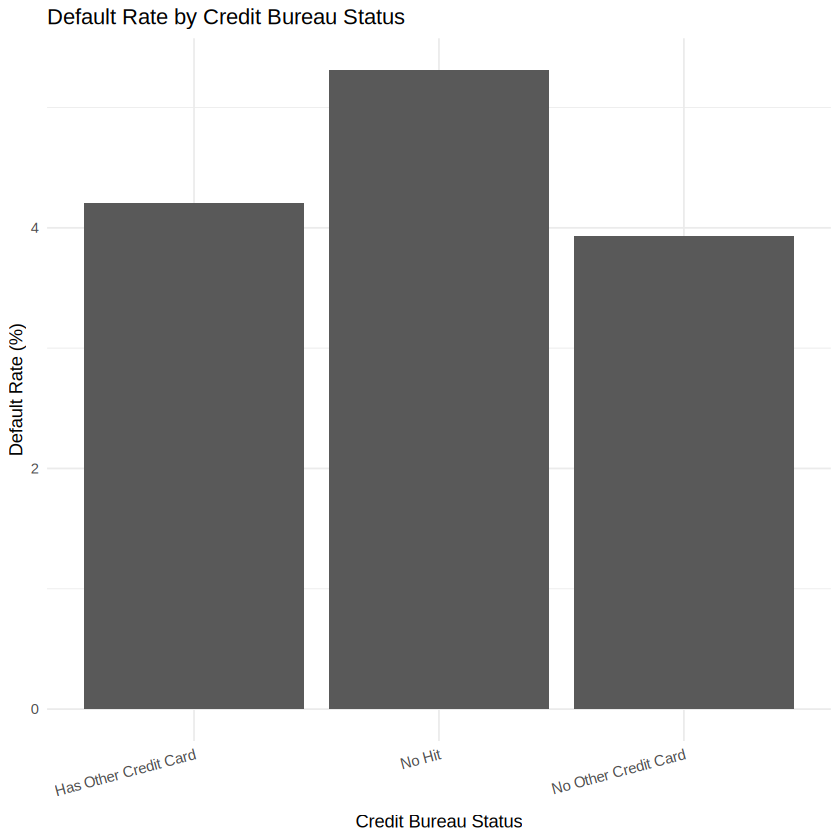

In [ ]:

ggplot(
  default.analysis,
  aes(x = Credit_Status, y = Default_Rate)
) +
  geom_col() +
  labs(
    title = "Default Rate by Credit Bureau Status",
    x = "Credit Bureau Status",
    y = "Default Rate (%)"
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(
      angle = 15,
      hjust = 1
    )
  )


In [19]:
# Prepare modelling dataset by removing missing values in the target variable
model.dat <- credit.dat %>%
  select(
    -any_of(c("Application.ID", "All_Bureau_Zero"))
  ) %>%
  filter(!is.na(Performance.Tag))

# Check target variable
table(model.dat$Performance.Tag)

# Check target values
unique(model.dat$Performance.Tag)

# WOE binning
bins <- scorecard::woebin(
  model.dat,
  y = "Performance.Tag",
  positive = "1"
)

# Display binning results
bins


    0     1 
66922  2948 

[1] 0 1

ℹ Creating woe binning ...


✔ Binning on 69870 rows and 18 columns in 00:00:05


variable,bin,count,count_distr,neg,pos,posprob,woe,bin_iv,total_iv,breaks,is_special_values
<chr>,<chr>,<int>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<lgl>
No.of.times.90.DPD.or.worse.in.last.6.months,"[-Inf,1)",54666,0.7823959,52872,1794,0.03281747,-0.2610253,0.04737765,0.1604581,1,FALSE
No.of.times.90.DPD.or.worse.in.last.6.months,"[1, Inf)",15204,0.2176041,14050,1154,0.07590108,0.6230126,0.11308047,0.1604581,Inf,FALSE
variable,bin,count,count_distr,neg,pos,posprob,woe,bin_iv,total_iv,breaks,is_special_values
<chr>,<chr>,<int>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<lgl>
No.of.times.60.DPD.or.worse.in.last.6.months,"[-Inf,1)",51871,0.74239302,50289,1582,0.03049874,-0.3366957,0.07232962,0.2095919,1,FALSE
No.of.times.60.DPD.or.worse.in.last.6.months,"[1,2)",11132,0.15932446,10348,784,0.07042760,0.5422613,0.06036194,0.2095919,2,FALSE
No.of.times.60.DPD.or.worse.in.last.6.months,"[2, Inf)",6867,0.09828252,6285,582,0.08475317,0.7429501,0.07690030,0.2095919,Inf,FALSE
variable,bin,count,count_distr,neg,pos,posprob,woe,bin_iv,total_iv,breaks,is_special_values
<chr>,<chr>,<int>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<lgl>


In [ ]:

# Calculate IV
iv.results <- scorecard::iv(
  model.dat,
  y = "Performance.Tag",
  positive = "1"
)

# Sort IV from highest to lowest
iv.results <- iv.results %>%
  arrange(desc(info_value))

# Display IV table

  print(iv.results)


In [ ]:
# Exclude Application ID
credit.stats <- credit.dat %>%
  select(-Application.ID) %>%
  select(where(is.numeric)) %>%
  psych::describe() %>%
  as.data.frame()

# Add variable names as a column
credit.stats$Variable <- rownames(credit.stats)

# Select and rename columns
 credit.stats %>%
  select(
    Variable,
    N = n,
    Mean = mean,
    SD = sd,
    Median = median,
    Minimum = min,
    Maximum = max,
    Skewness = skew,
    Kurtosis = kurtosis
  )

